In [1]:
# Loads the temperature data for Math 50 Assignment 3 into dataframes `mbh`
# and `hadcrut`.
# Data is loaded directly from math50-data (raw GitHub URLs), so this
# notebook runs as-is in Colab.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
%config InlineBackend.figure_format = 'svg'

In [2]:
MBH_URL = "https://raw.githubusercontent.com/elevien/math50-data/main/data/mbh99-nh-temperature.csv"
HADCRUT_URL = "https://raw.githubusercontent.com/elevien/math50-data/main/data/hadcrut5-nh-annual.csv"


def load_mbh():
    # columns: year, recon (reconstructed temperature, 1000-1980),
    # inst (the thermometer record MBH used, 1902-1998) and
    # se (reported standard error of recon, 1000-1901).
    # Missing values are NaN.
    return pd.read_csv(MBH_URL)


def load_hadcrut(mbh):
    # columns: year, temp (HadCRUT5 Northern Hemisphere annual temperature,
    # 1850-present), shifted so that its 1902-1980 average matches mbh.inst
    # (the two records use different reference periods).
    out = pd.read_csv(HADCRUT_URL)[["year", "temp"]]
    both = out.merge(mbh, on="year")
    both = both[(both.year >= 1902) & (both.year <= 1980)]
    out["temp"] = out["temp"] - (both["temp"] - both["inst"]).mean()
    return out


mbh = load_mbh()
hadcrut = load_hadcrut(mbh)
mbh.head()

,year,recon,inst,se
0,1000,0.0659,NaN,0.240346
1,1001,-0.1241,NaN,0.240347
2,1002,-0.1208,NaN,0.240346
3,1003,-0.1801,NaN,0.240347
4,1004,-0.0711,NaN,0.240347


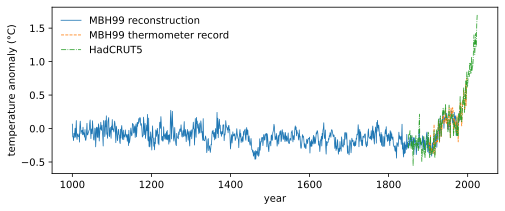

In [3]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(mbh.year, mbh.recon, lw=0.8, label="MBH99 reconstruction")
ax.plot(mbh.year, mbh.inst, "--", lw=0.8, label="MBH99 thermometer record")
ax.plot(hadcrut.year, hadcrut.temp, "-.", lw=0.8, label="HadCRUT5")
ax.set_xlabel("year")
ax.set_ylabel("temperature anomaly (°C)")
ax.legend(frameon=False)
plt.show()

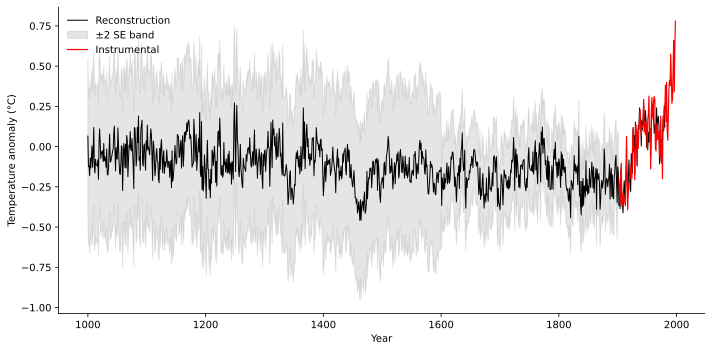

In [4]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))

# Plot the reconstruction line
ax.plot(mbh['year'], mbh['recon'], color='black', label='Reconstruction', linewidth=1)

# Add the standard error band (+- 2 * se)
lower_bound = mbh['recon'] - 2 * mbh['se']
upper_bound = mbh['recon'] + 2 * mbh['se']
ax.fill_between(mbh['year'], lower_bound, upper_bound, color='gray', alpha=0.2, label='±2 SE band')

# Overlay the instrumental data where available
ax.plot(mbh['year'], mbh['inst'], color='red', label='Instrumental', linewidth=1.2)

# Styling
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_xlabel('Year', fontsize=10)
ax.set_ylabel('Temperature anomaly (°C)', fontsize=10)
ax.legend(frameon=False, loc='upper left')
ax.tick_params(bottom=True, left=True)

plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3015: RuntimeWarning: Degrees of freedom <= 0 for slice
  c = cov(x, y, rowvar, dtype=dtype)
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2888: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2888: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)


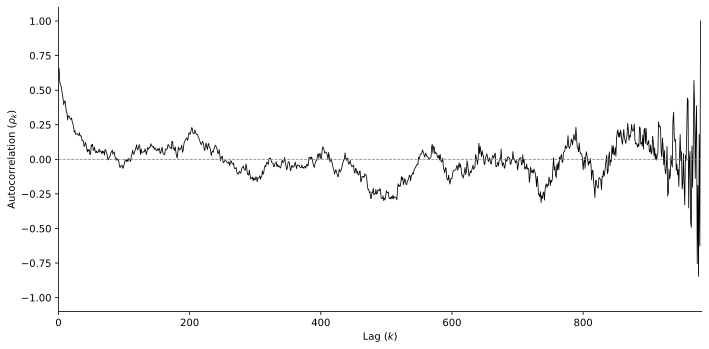

In [13]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Drop NaNs to compute autocorrelation on the continuous reconstructed series
recon_series = mbh['recon'].dropna()
N = len(recon_series)

# Compute autocorrelation for all possible lags k from 1 to N-1
lags = np.arange(1, N)
autocorr_values = [recon_series.autocorr(lag=k) for k in lags]

# Create a minimalist plot
fig, ax = plt.subplots(figsize=(10, 5))

# Plot autocorrelation coefficients as a time series spanning all lags
ax.plot(lags, autocorr_values, color='black', linewidth=0.8)
ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)

# Minimalist styling
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_xlabel('Lag ($k$)', fontsize=10)
ax.set_ylabel(r'Autocorrelation ($\rho_k$)', fontsize=10)
ax.set_xlim(0, N)
ax.set_ylim(-1.1, 1.1)
ax.tick_params(bottom=True, left=True)

plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3015: RuntimeWarning: Degrees of freedom <= 0 for slice
  c = cov(x, y, rowvar, dtype=dtype)
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2888: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2888: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)


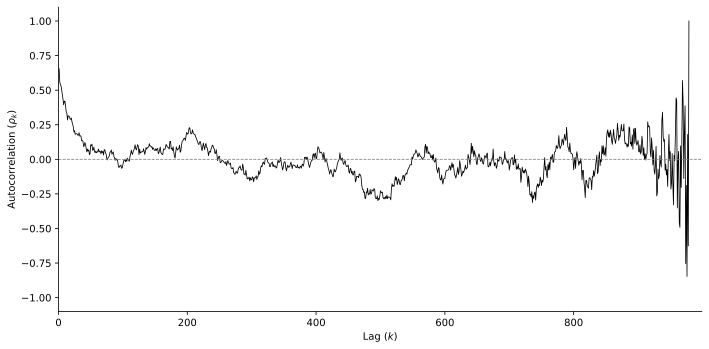

In [16]:
import matplotlib.pyplot as plt
import numpy as np

# Get the 'recon' series spanning the full index range of the mbh dataframe (length 999)
# and compute the autocorrelation for lags k from 1 to 998
full_recon = mbh['recon']
lags = np.arange(1, 999)
autocorr_values = [full_recon.autocorr(lag=k) for k in lags]

# Create a minimalist plot
fig, ax = plt.subplots(figsize=(10, 5))

# Plot the autocorrelation coefficient as a function of Lag k
ax.plot(lags, autocorr_values, color='black', linewidth=0.8)
ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)

# Minimalist styling
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_xlabel('Lag ($k$)', fontsize=10)
ax.set_ylabel(r'Autocorrelation ($\rho_k$)', fontsize=10)
ax.set_xlim(0, 999)
ax.set_ylim(-1.1, 1.1)
ax.tick_params(bottom=True, left=True)

plt.tight_layout()
plt.show()